# Деревья решений и случайный лес: кредитный скоринг

In [1]:
# Импорты и окружение.
import warnings
warnings.filterwarnings("ignore")  # глушим ворнинги sklearn/matplotlib, чтобы вывод был чистым
import numpy as np  # числа и linspace для сетки max_features
import pandas as pd  # таблицы: read_csv, DataFrame, медианы, submission
import matplotlib.pyplot as plt  # графики важностей, savefig в PNG, show
from sklearn.tree import DecisionTreeClassifier  # дерево решений для бинарной классификации
from sklearn.ensemble import RandomForestClassifier  # случайный лес без настройки и финальный
from sklearn.model_selection import GridSearchCV  # подбор гиперпараметров по кросс-валидации
from sklearn.metrics import roc_auc_score  # ROC-AUC как ориентир качества на train
print(np.__version__, pd.__version__)  # версии numpy/pandas для воспроизводимости

# Хелпер записи submission-файла.
# Формат как в ТЗ: столбец Delinquent90, индекс client_id начинается с 75000.
# Принимает вероятности класса 1 (predict_proba), сохраняет CSV с индексом.
def write_to_submission_file(predicted_proba, out_file):
    predicted = np.asarray(predicted_proba)  # вероятности класса 1 в numpy-массив
    idx = np.arange(75000, 75000 + len(predicted))  # индексы client_id с 75000 по ТЗ
    submission = pd.DataFrame({"Delinquent90": predicted}, index=idx)  # одна колонка-вероятность
    submission.index.name = "client_id"  # имя индекса как в train/test
    submission.to_csv(out_file)  # пишем CSV рядом с ноутбуком
    print(out_file, submission.shape)  # контроль: (75000, 1)
    print(submission.head().to_string())  # первые строки submission


2.4.6 3.1.0


## 1. Загрузка данных, пропуски, медианное заполнение

In [2]:
# Загрузка train/test, y=Delinquent90, info пропусков, медианы NumDependents/Income.
# Формулы нет: читаем CSV с index_col='client_id', считаем медианы, заполняем NaN.
train = pd.read_csv("credit_scoring_train.csv", index_col="client_id")  # train 75000x11 с целевой колонкой
test = pd.read_csv("credit_scoring_test.csv", index_col="client_id")  # test 75000x10 без Delinquent90
print(train.shape, test.shape)  # ждём (75000, 10) и (75000, 9) после выноса индекса
y = train["Delinquent90"]  # целевая переменная: 1 — просрочка 90+ дней
X_train = train.drop(columns=["Delinquent90"])  # признаки train без цели
X_test = test.copy()  # признаки test как есть
print(y.value_counts(normalize=True).round(4).to_string())  # баланс: positives около 6.7%
train.info()  # типы и non-null: ждём пропуски в NumDependents и Income
print(X_test.isna().sum().to_string())  # пропуски в test по каждой колонке
med_dep_train = X_train["NumDependents"].median()  # медиана иждивенцев на train
med_inc_train = X_train["Income"].median()  # медиана дохода на train
med_dep_test = X_test["NumDependents"].median()  # медиана иждивенцев на test
med_inc_test = X_test["Income"].median()  # медиана дохода на test
print(med_dep_train, med_inc_train)  # медианы train для заполнения
print(med_dep_test, med_inc_test)  # медианы test для контроля
X_train["NumDependents"] = X_train["NumDependents"].fillna(med_dep_train)  # NaN иждивенцев train -> медиана train
X_train["Income"] = X_train["Income"].fillna(med_inc_train)  # NaN дохода train -> медиана train
X_test["NumDependents"] = X_test["NumDependents"].fillna(med_dep_train)  # test тем же числом: без утечки из test
X_test["Income"] = X_test["Income"].fillna(med_inc_train)  # test тем же числом: без утечки из test
print(X_train.isna().sum().sum(), X_test.isna().sum().sum())  # ждём 0 0: пропусков не осталось


(75000, 10) (75000, 9)
Delinquent90
0    0.9332
1    0.0668
<class 'pandas.DataFrame'>
RangeIndex: 75000 entries, 0 to 74999
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   DIR                    75000 non-null  float64
 1   Age                    75000 non-null  float64
 2   NumLoans               75000 non-null  int64  
 3   NumRealEstateLoans     75000 non-null  int64  
 4   NumDependents          73084 non-null  float64
 5   Num30-59Delinquencies  75000 non-null  int64  
 6   Num60-89Delinquencies  75000 non-null  int64  
 7   Income                 60153 non-null  float64
 8   BalanceToCreditLimit   75000 non-null  float64
 9   Delinquent90           75000 non-null  int64  
dtypes: float64(5), int64(5)
memory usage: 5.7 MB
DIR                          0
Age                          0
NumLoans                     0
NumRealEstateLoans           0
NumDependents             2008
Num30-59Delin

## 2. Дерево решений глубины 3

In [3]:
# Дерево max_depth=3, random_state=17: fit, predict_proba на test, submission, ROC-AUC на train.
# ROC-AUC на train — оптимистичный ориентир (переобучение), а не честная оценка.
first_tree = DecisionTreeClassifier(max_depth=3, random_state=17)  # мелкое дерево по ТЗ
first_tree.fit(X_train, y)  # обучаем на всех 75k строк train
train_proba = first_tree.predict_proba(X_train)[:, 1]  # вероятности класса 1 на train
print(round(roc_auc_score(y, train_proba), 3))  # ROC-AUC на train как ориентир
first_pred = first_tree.predict(X_test)  # метки 0/1 на test (для контроля распределения)
print(pd.Series(first_pred).value_counts().to_string())  # сколько test отнесено к классу 1
first_proba = first_tree.predict_proba(X_test)[:, 1]  # вероятности класса 1 на test
write_to_submission_file(first_proba, "credit_scoring_first_tree.csv")  # первый submission


0.797
0    74340
1      660


credit_scoring_first_tree.csv (75000, 1)
           Delinquent90
client_id              
75000          0.020905
75001          0.282036
75002          0.020905
75003          0.020905
75004          0.020905


## 3. Подбор гиперпараметров дерева (GridSearchCV)

In [4]:
%%time
# Сетка дерева: max_depth 3..7, min_samples_leaf 5..12; random_state=17, n_jobs=-1, cv=5 (5-кратная по ТЗ).
# 5-кратная кросс-валидация по ТЗ; метрика по умолчанию — accuracy.
tree_grid = {"max_depth": list(range(3, 8)),  # глубина 3,4,5,6,7
             "min_samples_leaf": list(range(5, 13))}  # минимум листьев 5..12
tree_search = GridSearchCV(DecisionTreeClassifier(random_state=17),  # дерево с фикс. сидом
                           tree_grid, cv=5, n_jobs=-1)  # 5 фолдов, все ядра
tree_search.fit(X_train, y)  # перебор 5*8=40 комбинаций x 5 фолдов
print(tree_search.best_params_)  # лучшая комбинация сетки
print(round(tree_search.best_score_, 3))  # лучший средний скор CV, округление 3
tuned_proba = tree_search.predict_proba(X_test)[:, 1]  # вероятности лучшего дерева на test
write_to_submission_file(tuned_proba, "credit_scoring_tuned_tree.csv")  # submission настроенного дерева


{'max_depth': 5, 'min_samples_leaf': 11}
0.935
credit_scoring_tuned_tree.csv (75000, 1)
           Delinquent90
client_id              
75000          0.049232
75001          0.402135
75002          0.013663
75003          0.049232
75004          0.013663
CPU times: user 785 ms, sys: 718 ms, total: 1.5 s
Wall time: 6.66 s


## 4. Случайный лес без настройки

In [5]:
%%time
# RandomForestClassifier по умолчанию, random_state=17, n_jobs=-1: fit + submission.
# Замер времени ячейкой %%time: лес из 100 деревьев на 75k строк — самая долгая ячейка.
forest = RandomForestClassifier(random_state=17, n_jobs=-1)  # дефолт: 100 деревьев
forest.fit(X_train, y)  # обучаем лес на всех 75k строк
forest_proba = forest.predict_proba(X_test)[:, 1]  # вероятности класса 1 на test
write_to_submission_file(forest_proba, "credit_scoring_forest.csv")  # submission леса без настройки


credit_scoring_forest.csv (75000, 1)
           Delinquent90
client_id              
75000              0.07
75001              0.61
75002              0.00
75003              0.17
75004              0.00
CPU times: user 14.5 s, sys: 164 ms, total: 14.7 s
Wall time: 1.81 s


## 5. Подбор max_features леса (GridSearchCV)

In [6]:
%%time
# Сетка леса: max_features = np.linspace(.3, 1, 7); random_state=17, n_jobs=-1, cv=5 (5-кратная по ТЗ).
# 7 значений доли признаков x 5 фолдов; тяжело, смотрим время через %%time.
forest_grid = {"max_features": np.linspace(0.3, 1.0, 7)}  # 0.3, 0.4, ..., 1.0
forest_search = GridSearchCV(RandomForestClassifier(random_state=17, n_jobs=-1),  # лес с фикс. сидом
                             forest_grid, cv=5, n_jobs=-1)  # 5 фолдов, все ядра
forest_search.fit(X_train, y)  # перебор 7 комбинаций x 5 фолдов
print(forest_search.best_params_)  # лучшая доля признаков
print(round(forest_search.best_score_, 3))  # лучший средний скор CV, округление 3
tuned_forest_proba = forest_search.predict_proba(X_test)[:, 1]  # вероятности лучшего леса на test
write_to_submission_file(tuned_forest_proba, "credit_scoring_tuned_forest.csv")  # submission настроенного леса


{'max_features': np.float64(0.3)}
0.934


credit_scoring_tuned_forest.csv (75000, 1)
           Delinquent90
client_id              
75000              0.05
75001              0.61
75002              0.00
75003              0.15
75004              0.00
CPU times: user 13.3 s, sys: 451 ms, total: 13.7 s
Wall time: 1min 27s


## 6. Важности признаков лучшего леса

              feature  importance
 BalanceToCreditLimit    0.225870
                  DIR    0.170165
                  Age    0.160547
               Income    0.149931
             NumLoans    0.093448
Num60-89Delinquencies    0.065612
Num30-59Delinquencies    0.063031
        NumDependents    0.038538
   NumRealEstateLoans    0.032858


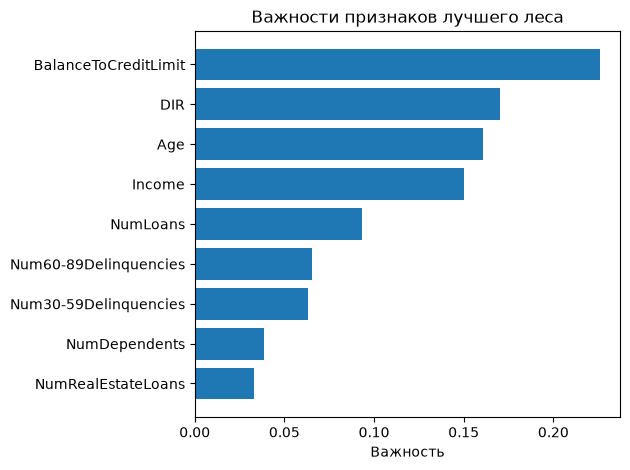

In [7]:
# feature_importances_ лучшего леса: DataFrame, сортировка, bar-график в PNG.
# Важность = суммарное уменьшение примеси (Gini) по всем сплитам признака во всех деревьях.
importances = pd.DataFrame({"feature": X_train.columns,  # имена 9 признаков
                            "importance": forest_search.best_estimator_.feature_importances_})  # важности лучшего леса
importances = importances.sort_values("importance", ascending=False)  # сортировка по убыванию
print(importances.to_string(index=False))  # таблица важностей
plt.figure()  # новая фигура под bar-график
plt.barh(importances["feature"], importances["importance"])  # горизонтальные бары важностей
plt.gca().invert_yaxis()  # самый важный признак сверху
plt.xlabel("Важность")  # подпись оси X
plt.title("Важности признаков лучшего леса")  # заголовок графика
plt.tight_layout()  # чтобы подписи не обрезались
plt.savefig("forest_importances.png")  # сохраняем PNG рядом с ноутбуком
plt.show()  # показываем график


## 7. Финальный лес: 300 деревьев с лучшими параметрами

In [8]:
%%time
# Финальный лес: n_estimators=300 + лучшие max_features из п.5, random_state=17, n_jobs=-1.
# Обучаем на всём train, predict_proba на test -> credit_scoring_final_forest.csv.
best_mf = forest_search.best_params_["max_features"]  # лучшая доля признаков из GridSearch
print(best_mf)  # контроль перенесённого параметра
final_forest = RandomForestClassifier(n_estimators=300, max_features=best_mf,  # 300 деревьев + лучший max_features
                                      random_state=17, n_jobs=-1)  # фикс. сид, все ядра
final_forest.fit(X_train, y)  # обучаем финальный лес на всех 75k строк
final_proba = final_forest.predict_proba(X_test)[:, 1]  # вероятности класса 1 на test
write_to_submission_file(final_proba, "credit_scoring_final_forest.csv")  # финальный submission


0.3


credit_scoring_final_forest.csv (75000, 1)
           Delinquent90
client_id              
75000          0.046667
75001          0.630000
75002          0.000000
75003          0.140000
75004          0.000000
CPU times: user 39.6 s, sys: 715 ms, total: 40.3 s
Wall time: 5.75 s
